### Data Collection

- The proposed dataset is the Medical Cost Personal Dataset on Kaggle.
-  The original project downloaded its GitHub CSV copy on 28 October 2026. This version uses that same included CSV.

In [2]:
# Import libraries
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt

# Reading the original CSV
df = pd.read_csv("insurance.csv")


#### Data Inspection and Understanding 

In [3]:
# view the first five records
df.head()

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


In [4]:
# Checking of the number of rows and columns
df.shape

(1338, 7)

In [5]:
# checking the exact column names
df.columns

Index(['age', 'sex', 'bmi', 'children', 'smoker', 'region', 'charges'], dtype='object')

In [6]:
# Checking data types and non-missing counts
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   object 
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   object 
 5   region    1338 non-null   object 
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), object(3)
memory usage: 73.3+ KB


In [7]:
# Summarising the numerical columns 
df.describe()

,age,bmi,children,charges
count,1338.000000,1338.000000,1338.000000,1338.000000
mean,39.207025,30.663397,1.094918,13270.422265
std,14.049960,6.098187,1.205493,12110.011237
min,18.000000,15.960000,0.000000,1121.873900
25%,27.000000,26.296250,0.000000,4740.287150
50%,39.000000,30.400000,1.000000,9382.033000
75%,51.000000,34.693750,2.000000,16639.912515
max,64.000000,53.130000,5.000000,63770.428010


## What the columns mean

| Column | Meaning |
|---|---|
| age | Age of the primary beneficiary, in years |
| sex | Sex label supplied in the source |
| bmi | Body mass index |
| children | Number of covered children or dependants, according to the source description |
| smoker | Recorded smoking status, yes or no |
| region | One of four US residential region labels |
| charges | Recorded individual medical charges, with an unspecified billing period |

In [8]:
df["sex"].unique()

array(['female', 'male'], dtype=object)

In [9]:
df["smoker"].unique()

array(['yes', 'no'], dtype=object)

In [10]:
df["region"].unique()

array(['southwest', 'southeast', 'northwest', 'northeast'], dtype=object)

In [11]:
df["smoker"].value_counts()

smoker
no     1064
yes     274
Name: count, dtype: int64

In [12]:
df["region"].value_counts()

region
southeast    364
southwest    325
northwest    325
northeast    324
Name: count, dtype: int64

In [13]:
df["children"].value_counts()

children
0    574
1    324
2    240
3    157
4     25
5     18
Name: count, dtype: int64

#### Data Cleaning

In [15]:
# counting missing values in each column
df.isnull().sum()

age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64

In [16]:
# Counting repeated rows after their first occurrence
df.duplicated().sum()

np.int64(1)

In [17]:
# Viewing the row flagged as repeated
df[df.duplicated()]

,age,sex,bmi,children,smoker,region,charges
581,19,male,30.59,0,no,northwest,1639.5631


- There is one repeated row after its first occurrence. I retain it because there is no person ID to confirm that it represents the same person. Two people could share the same values. The earlier full project checked this decision: removing it changed the overall mean by about $8.70.

- The following filters check for non-positive age, BMI or charges and negative child counts. Empty tables mean these checks found no records. These are basic structural checks, not a medical assessment. High charges are retained because a large number alone is not proof of an error.

In [18]:
df[df["age"] <= 0]

,age,sex,bmi,children,smoker,region,charges


In [19]:
df[df["bmi"] <= 0]

,age,sex,bmi,children,smoker,region,charges


In [20]:
df[df["charges"] <= 0]

,age,sex,bmi,children,smoker,region,charges


In [21]:
df[df["children"] < 0]

,age,sex,bmi,children,smoker,region,charges


#### Data Preparation

In [26]:
df["age_group"] = np.where(
    df["age"] < 30,
    "18-29",
    np.where(
        df["age"] < 40,
        "30-39",
        np.where(df["age"] < 50, "40-49", "50-64")
    )
)

In [27]:
# Checking the original age and the new group together
df[["age", "age_group"]].head()

,age,age_group
0,19,18-29
1,18,18-29
2,28,18-29
3,33,30-39
4,32,30-39


In [29]:
# Checking the number of records in each age group
df["age_group"].value_counts()

age_group
18-29    417
50-64    385
40-49    279
30-39    257
Name: count, dtype: int64

#### Descriptive and Comparative Analysis

In [30]:
# Converting the charges column into a Numpy array
charges = np.array(df["charges"])

In [31]:
mean_charge = np.mean(charges)
print("Mean Charge:", round(mean_charge, 2))

Mean Charge: 13270.42


In [32]:
deviation = charges - mean_charge
squared_deviation = deviation ** 2
sum_squared_deviation = np.sum(squared_deviation)
n = len(charges)
variance = sum_squared_deviation / (n-1)
standard_deviation = np.sqrt(variance)

print("Sample standard Deviation:", round(standard_deviation, 2))

Sample standard Deviation: 12110.01


- The median is the middle value. It helps us compare the typical charge with the mean when some charges are very large. The 50% row in df.describe() gives the same median. The following uses the simple .median() summary method.

In [33]:
median_charge = df["charges"].median()
print("Median CHarge:", round(median_charge, 2))

Median CHarge: 9382.03


In [35]:
# Charges by msoking status
# I want to use the groupby() pattern to calculate counts, means and medians separately so each result is by very easy to understand
df.groupby("smoker")["charges"].count()

smoker
no     1064
yes     274
Name: charges, dtype: int64

In [52]:
smoking_mean = df.groupby("smoker")["charges"].mean()
print(smoking_mean)

smoker
no      8434.268298
yes    32050.231832
Name: charges, dtype: float64


In [39]:
df.groupby("smoker")["charges"].median()

smoker
no      7345.40530
yes    34456.34845
Name: charges, dtype: float64

- Filter smokers and non-smokers into separate DataFrames. Calculate their mean difference and ratio using ordinary arithmetic

In [40]:
smokers = df[df["smoker"] == "yes"]
non_smokers = df[df["smoker"] == "no"]

In [41]:
smoker_mean = smokers["charges"].mean()
non_smoker_mean = non_smokers["charges"].mean()
mean_difference = smoker_mean - non_smoker_mean
mean_ratio = smoker_mean / non_smoker_mean

print("Smoker mean:", round(smoker_mean, 2))
print("Non-smoker mean:", round(non_smoker_mean, 2))
print("Mean difference:", round(mean_difference, 2))
print("Mean ratio:", round(mean_ratio, 2))

Smoker mean: 32050.23
Non-smoker mean: 8434.27
Mean difference: 23615.96
Mean ratio: 3.8


##### Charges by age group

In [42]:
df.groupby("age_group")["charges"].count()

age_group
18-29    417
30-39    257
40-49    279
50-64    385
Name: charges, dtype: int64

In [51]:
age_mean = df.groupby("age_group")["charges"].mean()
print(age_mean)

age_group
18-29     9182.487125
30-39    11738.784117
40-49    14399.203564
50-64    17902.552070
Name: charges, dtype: float64


In [45]:
df.groupby("age_group")["charges"].median()

age_group
18-29     3213.62205
30-39     6082.40500
40-49     8606.21740
50-64    12629.89670
Name: charges, dtype: float64

In [46]:
# Charges by sex, region and number of children 
df.groupby("sex")["charges"].count()

sex
female    662
male      676
Name: charges, dtype: int64

In [47]:
sex_mean = df.groupby("sex")["charges"].mean()
print(sex_mean)

sex
female    12569.578844
male      13956.751178
Name: charges, dtype: float64

In [48]:
df.groupby("region")["charges"].count()

region
northeast    324
northwest    325
southeast    364
southwest    325
Name: charges, dtype: int64

In [53]:
region_mean = df.groupby("region")["charges"].mean()
print(region_mean)

region
northeast    13406.384516
northwest    12417.575374
southeast    14735.411438
southwest    12346.937377
Name: charges, dtype: float64


In [54]:
df.groupby("region")["charges"].median()

region
northeast    10057.652025
northwest     8965.795750
southeast     9294.131950
southwest     8798.593000
Name: charges, dtype: float64

In [55]:
df.groupby("children")["charges"].count()

children
0    574
1    324
2    240
3    157
4     25
5     18
Name: charges, dtype: int64

In [56]:
children_mean = df.groupby("children")["charges"].mean()
print(children_mean)

children
0    12365.975602
1    12731.171832
2    15073.563734
3    15355.318367
4    13850.656311
5     8786.035247
Name: charges, dtype: float64


#### Data Visualisation and Validation

- I will be using the Pandas .plot(kind = "bar") pattern 
- The age and BMI subplots separate smokers and non-smokers through colours. This allows a visual comparison without adding an unfamiliar correlation calculation. Histograms and boxplots from the earlier version are omitted to stay closer to the demonstrated plotting methods

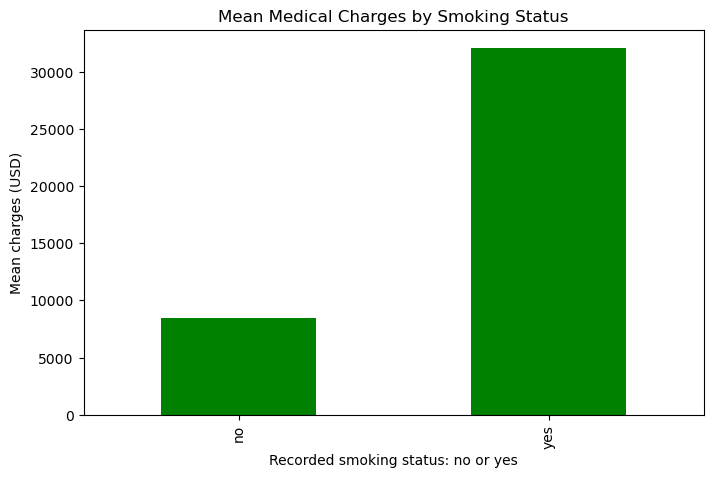

In [59]:
plt.figure(figsize = (8, 5))
smoking_mean.plot(kind = "bar", color = "green")
plt.title("Mean Medical Charges by Smoking Status")
plt.xlabel("Recorded smoking status: no or yes")
plt.ylabel("Mean charges (USD)")
plt.show()

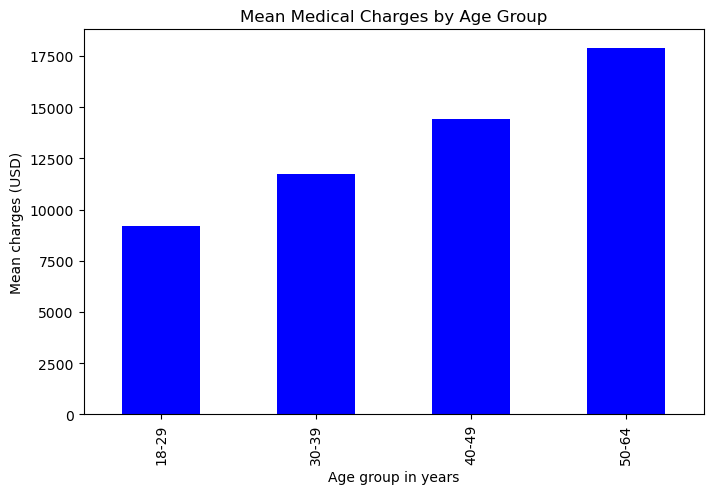

In [61]:
plt.figure(figsize = (8, 5))
age_mean.plot(kind = "bar", color = "blue")
plt.title("Mean Medical Charges by Age Group")
plt.xlabel("Age group in years")
plt.ylabel("Mean charges (USD)")
plt.show()

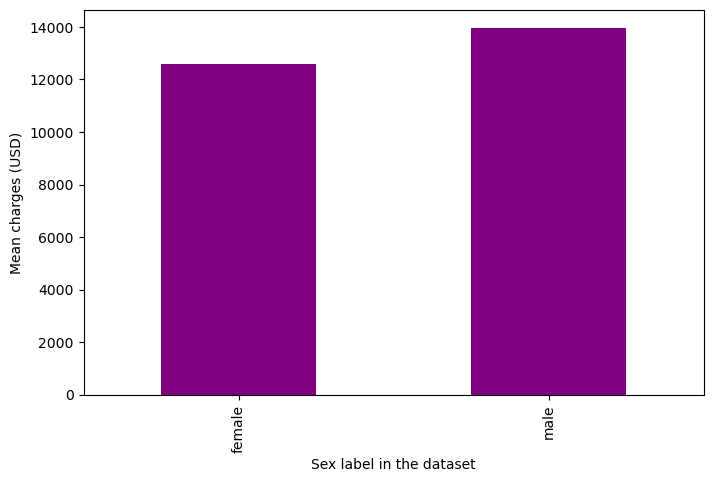

In [62]:
plt.figure(figsize = (8, 5))
sex_mean.plot(kind = "bar", color = "purple")
plt.xlabel("Sex label in the dataset")
plt.ylabel("Mean charges (USD)")
plt.show()

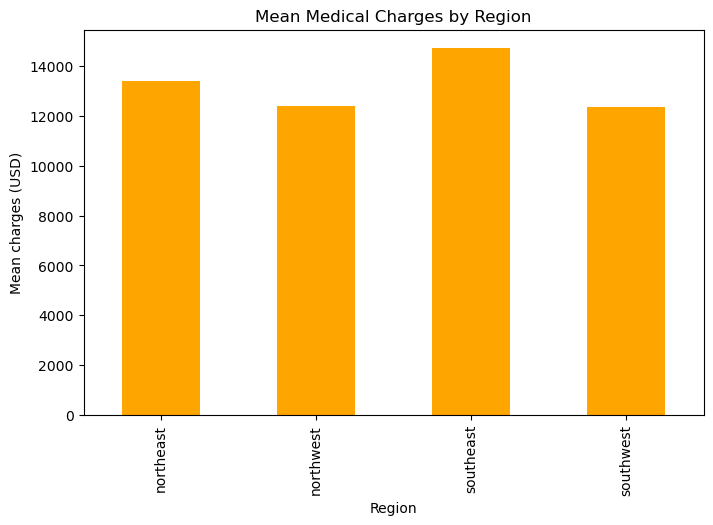

In [63]:
plt.figure(figsize = (8, 5))
region_mean.plot(kind = "bar", color = "orange")
plt.title("Mean Medical Charges by Region")
plt.xlabel("Region")
plt.ylabel("Mean charges (USD)")
plt.show()

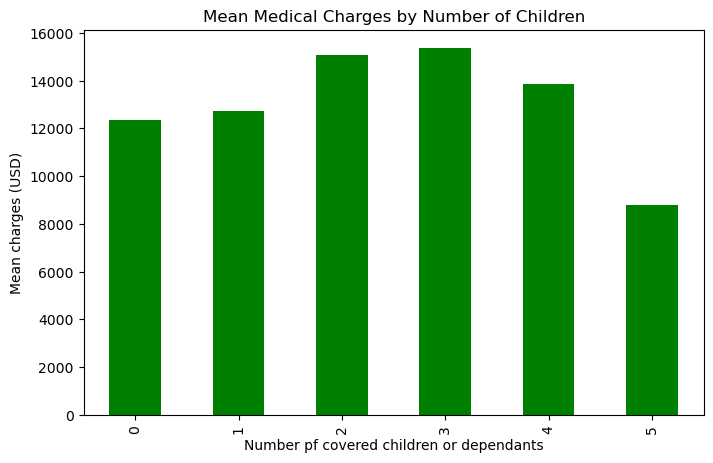

In [64]:
plt.figure(figsize = (8, 5))
children_mean.plot(kind = "bar", color = "green")
plt.title("Mean Medical Charges by Number of Children")
plt.xlabel("Number pf covered children or dependants")
plt.ylabel("Mean charges (USD)")
plt.show()

In [10]:
# Import libraries
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt


# Reading the original CSV
df = pd.read_csv("insurance.csv")

In [12]:
# Separate the data into smokers and non-smokers
non_smokers = df[df["smoker"] == "no"]
smokers = df[df["smoker"] == "yes"]

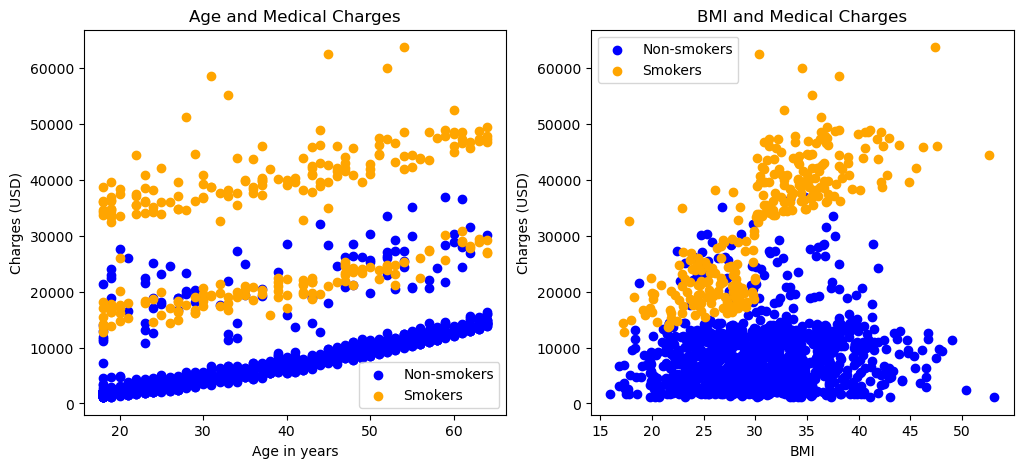

In [15]:
fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(12, 5))

axes[0].scatter(non_smokers["age"], non_smokers["charges"], label="Non-smokers", color="blue")
axes[0].scatter(smokers["age"], smokers["charges"], label="Smokers", color="orange")
axes[0].set_title("Age and Medical Charges")
axes[0].set_xlabel("Age in years")
axes[0].set_ylabel("Charges (USD)")
axes[0].legend()

axes[1].scatter(non_smokers["bmi"], non_smokers["charges"], label="Non-smokers", color="blue")
axes[1].scatter(smokers["bmi"], smokers["charges"], label="Smokers", color="orange")
axes[1].set_title("BMI and Medical Charges")
axes[1].set_xlabel("BMI")
axes[1].set_ylabel("Charges (USD)")
axes[1].legend()

plt.show()

##### Scatter plot interpretation: 
- charges generally increase with age, with considerable variation between records. BMI shows different visual patterns across smoking groups. Many smokers with higher BMI values also have higher charges. The plots show associations and do not establish causes.
##### Distribution of medical charges
- A histogram groups numerical values into intervals and counts how many records fall in each interval. Unlike the category bar charts above, its x-axis represents ranges of charges.

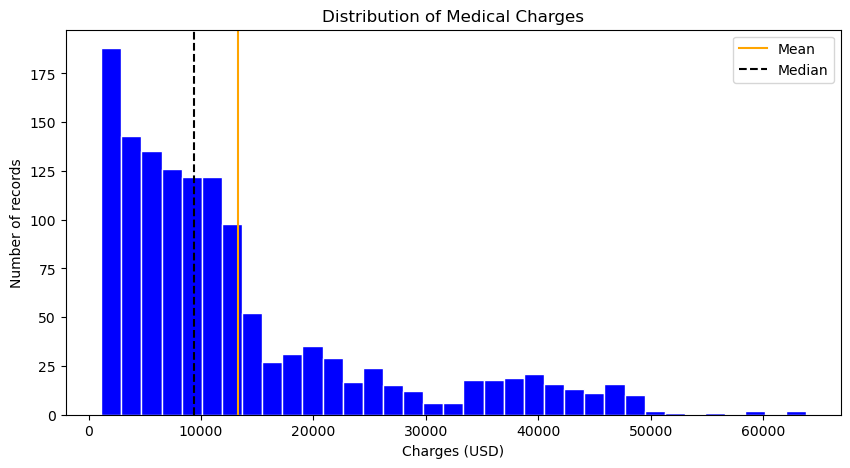

In [19]:
plt.figure(figsize = (10, 5))
plt.hist(df["charges"], bins = 35, color = "blue", edgecolor = "white")
plt.axvline(df["charges"].mean(), color = "orange", label = "Mean")
plt.axvline(df["charges"].median(), color = "black", linestyle = "--", label = "Median")
plt.title("Distribution of Medical Charges")
plt.xlabel("Charges (USD)")
plt.ylabel("Number of records")
plt.legend()
plt.show()

##### Interpretation: 
- Most records occur toward the lower end, with a long tail of higher charges. The mean of 13,270.42 lies above the median of 9,382.03. A few large values can pull the mean upward, so both summaries are useful. The billing period is unconfirmed.

##### Smoking status boxplot
The earlier smoking bar chart compares averages. A boxplot shows the spread of the charges in each group

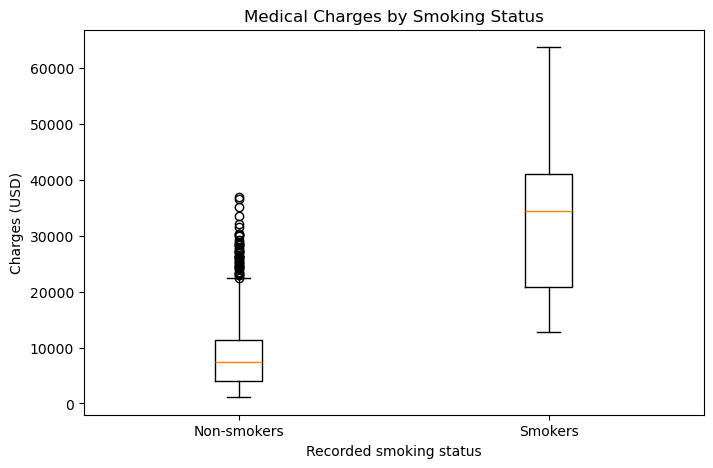

In [22]:
plt.figure(figsize = (8, 5))
plt.boxplot([non_smokers["charges"], smokers["charges"]])
plt.xticks([1, 2], ["Non-smokers", "Smokers"])
plt.title("Medical Charges by Smoking Status")
plt.xlabel("Recorded smoking status")
plt.ylabel("Charges (USD)")
plt.show()

##### Interpretation: 
- The smoker median is 34,456.35, compared with 7,345.41 for non-smokers. The height of the boxes also shows different spreads. Some non-smokers have high charges beyond their group's upper whisker, so a group average should not be treated as every person's charge.

##### Mean and median charges by age group
The existing age chart shows the mean alone. This chart places the mean and median side by side.

In [26]:

# Create age groups
df["age_group"] = np.where(
    df["age"] < 30,
    "18-29",
    np.where(
        df["age"] < 40,
        "30-39",
        np.where(df["age"] < 50, "40-49", "50-64")
    )
)

# Check the new column
df[["age", "age_group"]].head()

,age,age_group
0,19,18-29
1,18,18-29
2,28,18-29
3,33,30-39
4,32,30-39


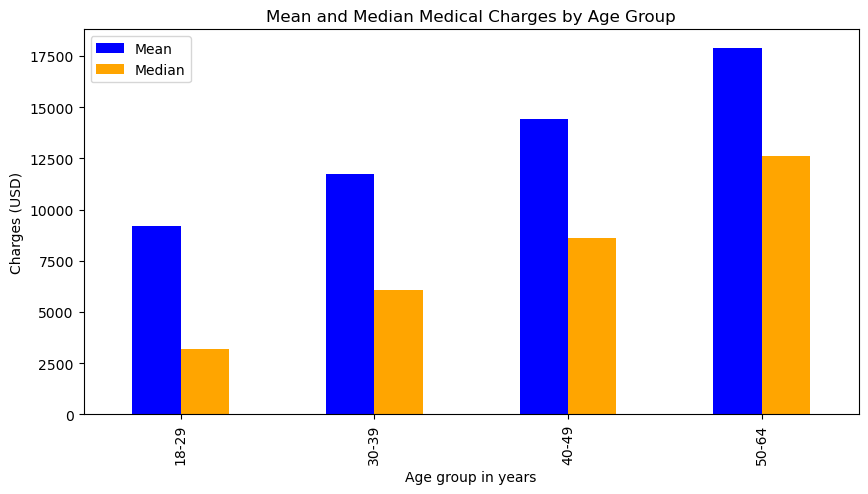

In [27]:
age_comparison = pd.DataFrame({
    "Mean": df.groupby("age_group") ["charges"].mean(),
    "Median": df.groupby("age_group") ["charges"].median()
})

age_comparison.plot(kind = "bar", figsize = (10, 5), color = ["blue", "orange"])
plt.title("Mean and Median Medical Charges by Age Group")
plt.xlabel("Age group in years")
plt.ylabel("Charges (USD)")
plt.legend()
plt.show()

##### Interpretation: 
Both the mean and median increase across the selected age bands. The mean exceeds the median in every band, showing that the difference between the two overall summaries also appears within each age band. These comparisons do not control for smoking status or other characteristics

##### Numerical correlations
Correlation summarises a linear relationship between two numerical variables. A value near +1 indicates a strong positive linear relationship, a value near -1 indicates a strong negative linear relationship, and a value near 0 indicates little linear relationship. A near-zero value does not rule out a nonlinear pattern.

In [30]:
numerical_data = df[["age", "bmi", "children", "charges"]]
correlation = numerical_data.corr()
correlation

,age,bmi,children,charges
age,1.000000,0.109272,0.042469,0.299008
bmi,0.109272,1.000000,0.012759,0.198341
children,0.042469,0.012759,1.000000,0.067998
charges,0.299008,0.198341,0.067998,1.000000


##### Correlation heatmap
A heatmap uses colours to display the values in the correlation table

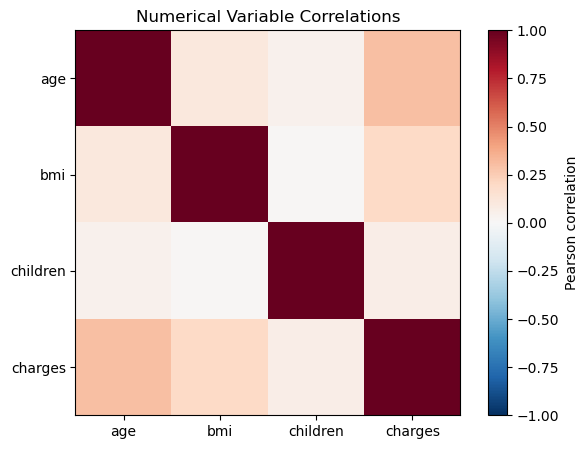

In [32]:
plt.figure(figsize = (7, 5))
plt.imshow(correlation, cmap = "RdBu_r", vmin = -1, vmax = 1)
plt.colorbar(label = "Pearson correlation")
plt.xticks([0, 1, 2, 3], ["age", "bmi", "children", "charges"])
plt.yticks([0, 1, 2, 3,], ["age", "bmi", "children", "charges"])
plt.title("Numerical Variable Correlations")
plt.show()

##### Interpretation: 
The overall correlations with charges are approximately 0.30 for age, 0.20 for BMI and 0.07 for children. The diagonal is 1 because each variable is perfectly correlated with itself. These are pooled, unadjusted linear relationships. The smoking-group scatter plots show why an overall coefficient may hide different patterns between groups. Correlation does not prove causation

#### Checking the prepared data 

In [33]:
df.shape

(1338, 8)

In [35]:
df.isnull().sum()

age          0
sex          0
bmi          0
children     0
smoker       0
region       0
charges      0
age_group    0
dtype: int64

In [37]:
smoking_count = df.groupby("smoker")["charges"].count()
age_count = df.groupby("age_group")["charges"].count()

print("Total records:", len(df))
print("Smoking group total:", smoking_count.sum())
print("Age group total:", age_count.sum())

Total records: 1338
Smoking group total: 1338
Age group total: 1338


##### Validation result: 
My prepared dataset has 1,338 rows and eight columns, including the new age-group column. Missing-value counts remain zero, and the smoking and age-group totals both equal 1,338. No rows were lost during preparation

#### Interpretation and Reporting

##### Findings from this dataset
- Mean charges are $13,270.42, while median charges are $9,382.03. The larger mean indicates that high charges pull the average above the middle value.
- Smokers have mean charges of $32,050.23, compared with $8,434.27 for non-smokers. The mean ratio is 3.80. This is an unadjusted group comparison, not proof that smoking alone caused the difference.
- Mean charges increase across the selected age groups, from $9,182.49 for ages 18–29 to $17,902.55 for ages 50–64.
- The scatter plots show different BMI patterns in the smoking groups. Among smokers, many high-BMI records also have high charges. The visual pattern does not establish a medical or causal conclusion.
- The southeast has the highest regional mean, but the northeast has the highest regional median. The composition of the groups may contribute to the differences.
- Charges do not rise consistently with the number of children. The four- and five-child groups are small, with only 25 and 18 records.

#### Limitations

The original collector, sampling design, real-person origin, collection period and billing period are unconfirmed. There is no person ID. The data omit medical history and plan details. These results describe the included records and should not be generalised to all insured people or current premiums.

In [39]:
# Saving the prepared data 
df.to_csv("insurance_cleaned.csv", index=False)

In [40]:
df.head()

,age,sex,bmi,children,smoker,region,charges,age_group
0,19,female,27.900,0,yes,southwest,16884.92400,18-29
1,18,male,33.770,1,no,southeast,1725.55230,18-29
2,28,male,33.000,3,no,southeast,4449.46200,18-29
3,33,male,22.705,0,no,northwest,21984.47061,30-39
4,32,male,28.880,0,no,northwest,3866.85520,30-39
